In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Feature importance
from sklearn.inspection import permutation_importance

# Save model
import joblib

In [2]:
from pathlib import Path
filename = "Tableau BlinkIT Grocery Project U16955293080 (4).xlsx"
candidates = [
    Path("../data") / filename,
    Path("data") / filename,
    Path(filename),
    Path(r"E:/PROJECT/blinkit-sales-analysis/data") / filename,
    Path(r"E:/PROJECT/Blinkit/data") / filename,
]
data_path = next((p for p in candidates if p.exists()), candidates[0])
print(f"Loading data from: {data_path}")
df = pd.read_excel(data_path)
df.head()


Loading data from: ..\data\Tableau BlinkIT Grocery Project U16955293080 (4).xlsx


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names and data types
print(df.info())

# Statistical summary
display(df.describe(include="all"))

# Missing values
print(df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Shape: (8523, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB
None


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
count,8523,7060.000000,8523,8523.000000,8523,8523.000000,8523,8523.000000,6113,8523,8523,8523.000000
unique,1559,NaN,5,NaN,16,NaN,10,NaN,3,3,4,NaN
top,FDW13,NaN,Low Fat,NaN,Fruits and Vegetables,NaN,OUT027,NaN,Medium,Tier 3,Supermarket Type1,NaN
freq,10,NaN,5089,NaN,1232,NaN,935,NaN,2793,3350,5577,NaN
mean,NaN,12.857645,NaN,0.066132,NaN,140.992782,NaN,1997.831867,NaN,NaN,NaN,2181.288914
std,NaN,4.643456,NaN,0.051598,NaN,62.275067,NaN,8.371760,NaN,NaN,NaN,1706.499616
min,NaN,4.555000,NaN,0.000000,NaN,31.290000,NaN,1985.000000,NaN,NaN,NaN,33.290000
25%,NaN,8.773750,NaN,0.026989,NaN,93.826500,NaN,1987.000000,NaN,NaN,NaN,834.247400
50%,NaN,12.600000,NaN,0.053931,NaN,143.012800,NaN,1999.000000,NaN,NaN,NaN,1794.331000
75%,NaN,16.850000,NaN,0.094585,NaN,185.643700,NaN,2004.000000,NaN,NaN,NaN,3101.296400


Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64
Duplicate rows: 0


In [4]:
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

# Remove rows where the target is missing or invalid
df["Item_Outlet_Sales"] = pd.to_numeric(df["Item_Outlet_Sales"], errors="coerce")

df = df.dropna(subset=["Item_Outlet_Sales"])

print("Shape after cleaning:", df.shape)
print(df["Item_Fat_Content"].value_counts())

Shape after cleaning: (8523, 12)
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


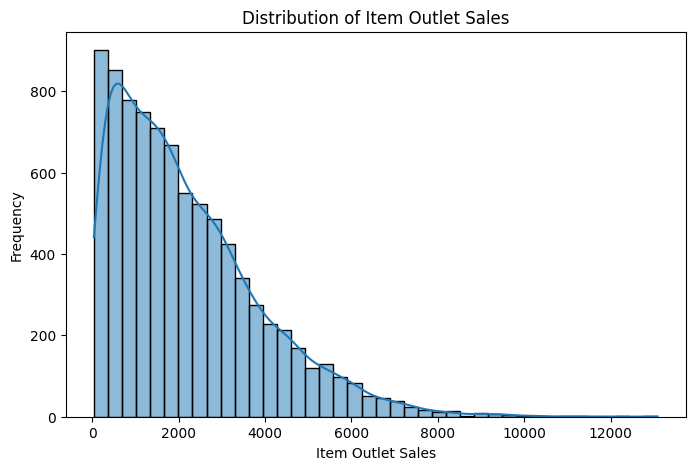

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Item_Outlet_Sales"], bins=40, kde=True)

plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Frequency")

plt.show()

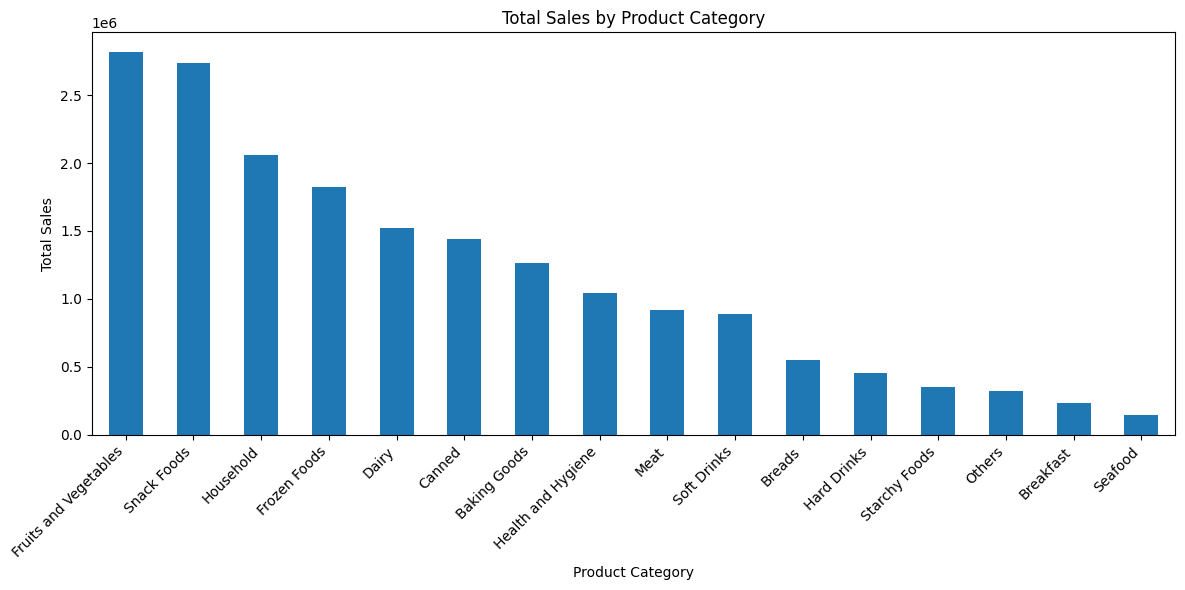

In [6]:
category_sales = (
    df.groupby("Item_Type")["Item_Outlet_Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

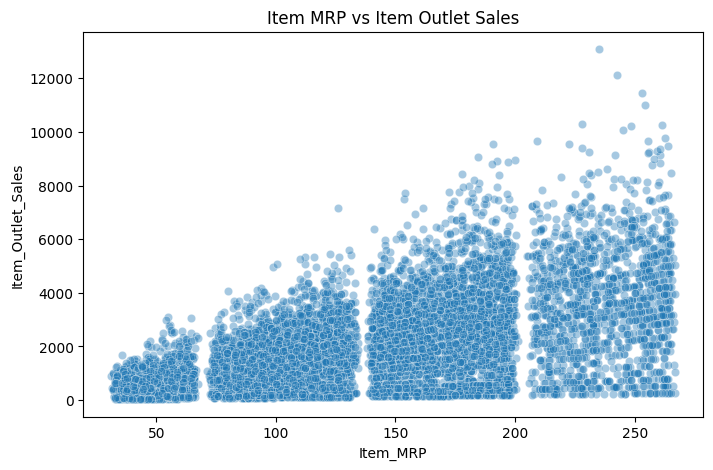

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Item_MRP",
    y="Item_Outlet_Sales",
    alpha=0.4
)

plt.title("Item MRP vs Item Outlet Sales")
plt.show()


In [8]:
features = [
    "Item_Weight",
    "Item_Fat_Content",
    "Item_Visibility",
    "Item_Type",
    "Item_MRP",
    "Outlet_Establishment_Year",
    "Outlet_Size",
    "Outlet_Location_Type",
    "Outlet_Type"
]

X = df[features]

y = df["Item_Outlet_Sales"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (8523, 9)
Target shape: (8523,)


In [9]:
numeric_features = [
    "Item_Weight",
    "Item_Visibility",
    "Item_MRP",
    "Outlet_Establishment_Year"
]

categorical_features = [
    "Item_Fat_Content",
    "Item_Type",
    "Outlet_Size",
    "Outlet_Location_Type",
    "Outlet_Type"
]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (6818, 9)
Testing features: (1705, 9)
Training target: (6818,)
Testing target: (1705,)


In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [12]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [14]:
models = {
    "Dummy Regressor": DummyRegressor(strategy="median"),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

In [15]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict sales
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print(f"\n{name}")
    print(f"MAE:  {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²:   {r2:.4f}")


Dummy Regressor
MAE:  1272.45
RMSE: 1673.71
R²:   -0.0307

Ridge Regression
MAE:  791.67
RMSE: 1069.14
R²:   0.5794

Random Forest
MAE:  764.10
RMSE: 1093.13
R²:   0.5604

Extra Trees
MAE:  795.17
RMSE: 1143.30
R²:   0.5191


In [16]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df)

,Model,MAE,RMSE,R2 Score
1,Ridge Regression,791.673111,1069.143767,0.579440
2,Random Forest,764.098753,1093.130211,0.560358
3,Extra Trees,795.168874,1143.303378,0.519074
0,Dummy Regressor,1272.452749,1673.712997,-0.030664


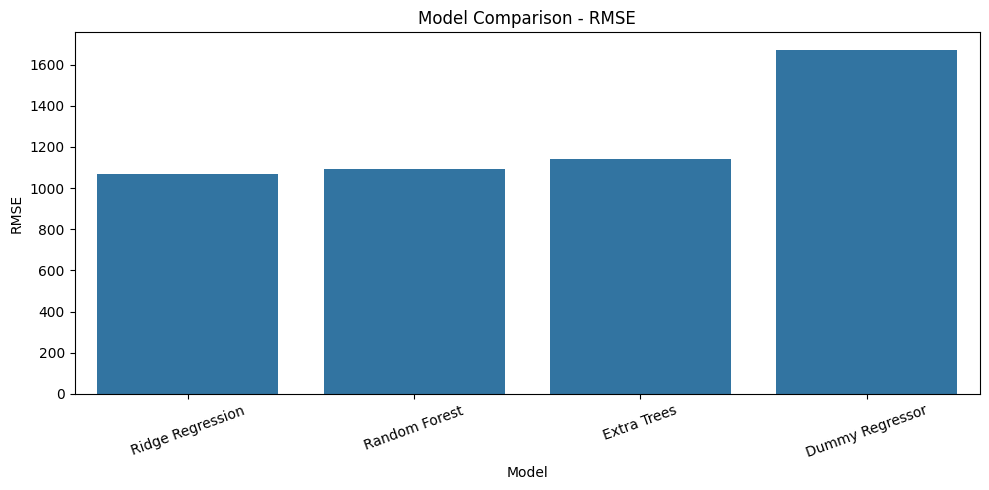

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [18]:
non_baseline_results = results_df[
    results_df["Model"] != "Dummy Regressor"
]

best_model_name = non_baseline_results.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Ridge Regression


In [19]:
y_pred_best = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred_best
})

display(comparison.head(10))

,Actual Sales,Predicted Sales
0,1743.0644,1359.061389
1,356.8688,764.963239
2,377.5086,818.420019
3,5778.4782,4226.268024
4,2356.9320,3291.572100
5,865.5400,577.614699
6,4613.9940,4750.512980
7,2410.8618,2049.936965
8,1948.1308,1392.998842
9,1937.4780,2785.560239


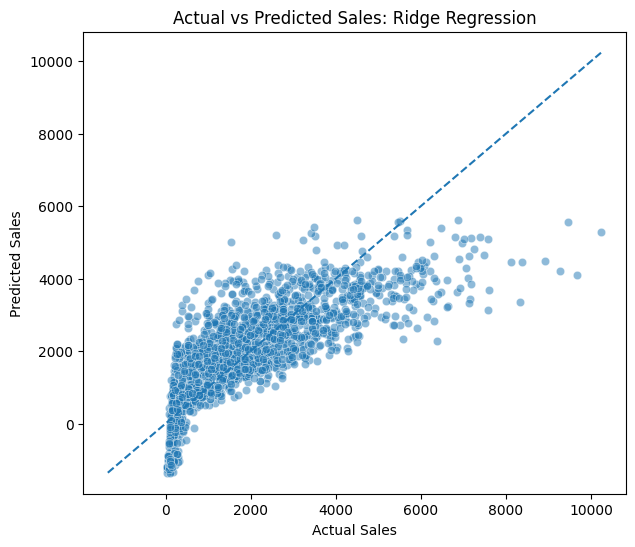

In [20]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_best,
    alpha=0.5
)

# Reference line: perfect predictions
lower = min(y_test.min(), y_pred_best.min())
upper = max(y_test.max(), y_pred_best.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted Sales: {best_model_name}")

plt.show()

In [21]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
4,Item_MRP,664.751339
8,Outlet_Type,594.383003
5,Outlet_Establishment_Year,52.319367
6,Outlet_Size,32.923937
7,Outlet_Location_Type,19.752760
1,Item_Fat_Content,0.519317
0,Item_Weight,0.111348
2,Item_Visibility,-0.544201
3,Item_Type,-1.697402


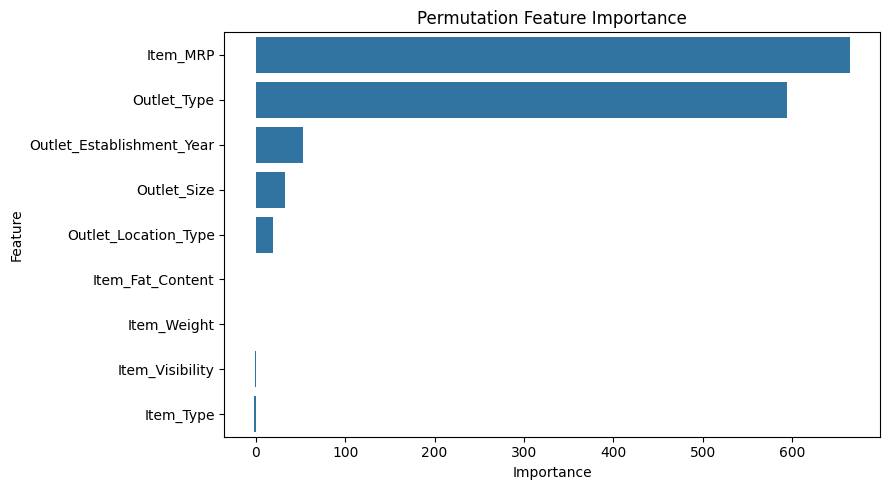

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.tight_layout()

plt.show()

In [23]:
new_data = pd.DataFrame([{
    "Item_Weight": 12.0,
    "Item_Fat_Content": "Low Fat",
    "Item_Visibility": 0.05,
    "Item_Type": "Snack Foods",
    "Item_MRP": 150.0,
    "Outlet_Establishment_Year": 2004,
    "Outlet_Size": "Medium",
    "Outlet_Location_Type": "Tier 2",
    "Outlet_Type": "Supermarket Type1"
}])

predicted_sales = best_model.predict(new_data)

print(f"Selected model: {best_model_name}")
print(f"Predicted sales: {predicted_sales[0]:.2f}")

Selected model: Ridge Regression
Predicted sales: 2420.29


In [24]:
joblib.dump(
    best_model,
    "blinkit_sales_prediction_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [25]:
loaded_model = joblib.load(
    "blinkit_sales_prediction_model.joblib"
)

predictions = loaded_model.predict(new_data)

print("Predicted sales:", predictions[0])

Predicted sales: 2420.294069852901


In [26]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/sales_prediction_model.joblib"
)

['models/sales_prediction_model.joblib']